
# Figure 8 — Socio-cultural and local-economy scenario outcomes

**Executed Python/Matplotlib figure for Section 4.5.3.** This notebook implements separately specified calculations for a **service-quality model index, cultural-sustainability model index, number of modeled vendors, and potential gross daily turnover per vendor**. It does **not** claim observed service outcomes, measured cultural preservation, or vendor net income.

The demand and ticket-receipt inputs use **the same 2024 observational anchor and scenario parameters as Figures 6 and 7**, with the model period 2025–2045. The service, cultural and vendor behavioral equations and their coefficient choices are drawn from the three legacy subsystem notebooks; here, their driver is annual-average admissions converted to a constant value for each simulated calendar day. It is a **scenario calculation** not a rerun or empirical recalibration of the complete legacy daily stock-and-flow models.

Source notebooks in the research GitHub repository:
- `Tourism_Services_Subsystem.ipynb` (training, decay and index ceiling)
- `Cultural_Preservation_Subsystem.ipynb` (cultural erosion, pressure, revitalization and threshold)
- `Economic_Subsystem_of_the_Local_Community_in_the_Tourism_Sector.ipynb` (vendor entry/exit, gross-per-vendor proxy and assumed cap)

**Interpretation boundaries:** The annual average is an admission flow and not a count simultaneously present. The assumed 85% fiscal transfer is a scenario-accounting device, **not an authorized allocation of Indonesian non-tax state receipts**. The expenditure and vendor proxies are not observed income or profit; **all visitors' assumed spending is assigned to the modeled vendors** as a deliberately stylized mechanism. The index of 100 is a fixed model ceiling. A cultural index of 60 is a researcher-specified threshold, not a measured Tengger cultural tipping point.


In [1]:

from pathlib import Path
from calendar import isleap
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

OUT = Path.cwd()
OBSERVED_2024_DOM = 465_770
OBSERVED_2024_FOR = 19_926
OBSERVED_2024_DAYS = 366
START_YEAR, END_YEAR = 2025, 2045
BAU_GROWTH = 0.0468
INT_GROWTH = 0.035
ASSUMED_ELASTICITY = -0.504
PRICE_INCREASE_DOM = 0.08
PRICE_INCREASE_FOR = 0.25
TICKET_DOM_WEEKDAY = 54_000
TICKET_DOM_HOLIDAY = 79_000
TICKET_FOREIGN = 255_000
ASSUMED_WEEKDAY_SHARE = 5/7
TICKET_DOM_BLEND = (ASSUMED_WEEKDAY_SHARE*TICKET_DOM_WEEKDAY
                    + (1-ASSUMED_WEEKDAY_SHARE)*TICKET_DOM_HOLIDAY)

# Financial bookkeeping of hypothetical scenario resources, not government spending authority.
INITIAL_BUDGET_IDR = 3_976_500_000
ASSUMED_MODEL_BUDGET_FRACTION = 0.85
ASSUMED_YEARLY_ABSORPTION = 0.90
DAILY_ABSORPTION = 1-(1-ASSUMED_YEARLY_ABSORPTION)**(1/365)

# Service subsystem assumptions, stock units are skill points / 10.
INITIAL_SKILL_STOCK = 712  # modeled quality index starts at 71.2 on 1 January 2025
SKILL_DECAY_DAILY = 1-(1-0.18)**(1/365)
SKILL_POINTS_PER_TRAINING = 1.5
BAU_TRAINING_SHARE = 0.015
INT_TRAINING_SHARE = 0.03
BAU_TRAINING_COST_IDR = 3_000_000
INT_TRAINING_COST_IDR = 2_000_000
MAX_SKILL_STOCK = 1000  # service-quality model index ceiling = 100

# Culture subsystem assumptions, not observed cultural state.
INITIAL_CULTURE_INDEX = 80.0
NATURAL_CULTURE_EROSION_DAILY = 1-(1-0.005)**(1/365)
CULTURE_PRESSURE_PER_ADMISSION = 0.0000045
REVITALIZATION_COST_PER_INDEX_POINT = 350_000_000
BAU_CULTURE_SHARE = 0.005
INT_CULTURE_SHARE = 0.025
CULTURE_REFERENCE = 60.0

# Local economic subsystem: gross turnover per vendor proxy, NOT net income.
INITIAL_VENDOR_COUNT = 200.0
ASSUMED_VISITOR_SPENDING_IDR = 75_000
VENDOR_ATTRACTION_COEFF = 0.0005
DAILY_VENDOR_CHURN = 1-(1-0.05)**(1/365)
ASSUMED_GROSS_TURNOVER_REFERENCE = 122_778  # model trigger, NOT verified net income
INTERVENTION_VENDOR_CAP = 450.0

assert OBSERVED_2024_DOM+OBSERVED_2024_FOR == 485_696
assert all(x >= 0 for x in [BAU_TRAINING_SHARE, INT_TRAINING_SHARE,
                            BAU_CULTURE_SHARE,INT_CULTURE_SHARE])
print('Reference annual-average admissions (2024):', round(485696/366, 2))
print('Simulation years:', START_YEAR, 'through', END_YEAR)


Reference annual-average admissions (2024): 1327.04
Simulation years: 2025 through 2045



## 1. Reproduce the visitor-demand and ticket-receipt inputs used in Figures 6–7

BAU daily admission averages increase by 4.68% annually. The intervention is aligned with BAU in 2025, then applies 3.5% annual growth and one-time domestic/foreign price-response multipliers in 2026, with elasticity set to −0.504. Domestic and international ticket prices use the same tariffs and assumed weekday blend as Figure 7.


In [2]:

base_dom = OBSERVED_2024_DOM / OBSERVED_2024_DAYS
base_for = OBSERVED_2024_FOR / OBSERVED_2024_DAYS
bau_dom, bau_for = base_dom, base_for
int_dom, int_for = base_dom, base_for
admission_rows=[]
for year in range(START_YEAR, END_YEAR+1):
    calendar_days = 366 if isleap(year) else 365
    bau_dom *= (1+BAU_GROWTH)
    bau_for *= (1+BAU_GROWTH)
    if year == 2025:
        int_dom, int_for = bau_dom, bau_for
    else:
        int_dom *= (1+INT_GROWTH)
        int_for *= (1+INT_GROWTH)
        if year == 2026:
            int_dom *= (1+ASSUMED_ELASTICITY*PRICE_INCREASE_DOM)
            int_for *= (1+ASSUMED_ELASTICITY*PRICE_INCREASE_FOR)
    int_dom_price = TICKET_DOM_BLEND*(1+PRICE_INCREASE_DOM if year>=2026 else 1)
    int_for_price = TICKET_FOREIGN*(1+PRICE_INCREASE_FOR if year>=2026 else 1)
    admission_rows.append({
        'year':year,'calendar_days':calendar_days,
        'BAU_admissions_day':bau_dom+bau_for,
        'INT_admissions_day':int_dom+int_for,
        'BAU_gross_ticket_IDR_day':bau_dom*TICKET_DOM_BLEND+bau_for*TICKET_FOREIGN,
        'INT_gross_ticket_IDR_day':int_dom*int_dom_price+int_for*int_for_price,
    })
visits=pd.DataFrame(admission_rows)
assert round(visits.iloc[-1]['BAU_admissions_day'])==3468
assert round(visits.iloc[-1]['INT_admissions_day'])==2643
assert int(visits.loc[visits.BAU_admissions_day>=2752,'year'].iloc[0])==2040
print('Visitors and ticket proxy check (same inputs as Figures 6–7):')
display(visits.loc[visits.year.isin([2025,2026,2045]),
                   ['year','BAU_admissions_day','INT_admissions_day',
                   'BAU_gross_ticket_IDR_day','INT_gross_ticket_IDR_day']].round(2))


Visitors and ticket proxy check (same inputs as Figures 6–7):


,year,BAU_admissions_day,INT_admissions_day,BAU_gross_ticket_IDR_day,INT_gross_ticket_IDR_day
0,2025,1389.14,1389.14,9.598423e+07,9.598423e+07
1,2026,1454.16,1374.74,1.004763e+08,1.038082e+08
20,2045,3467.54,2642.94,2.395930e+08,1.995714e+08



## 2. Simulate the three subsystem outcomes

For each scenario and simulated day, the model uses the annual-average demand and hypothetical ticket receipts for that year. The budget state accumulates a scenario-assumed 85% of gross tickets and decays through an assumed 90% annual expenditure fraction; training and preservation allocations are percentages of simulated expenditure. Service skill stock changes through paid training minus annualized skill decay (capped at 1,000 points). The cultural index changes through model spending, assumed erosion and assumed visitor-pressure coefficients. Vendor count changes through a stylized attraction–churn rule with a 450-vendor cap under intervention. **All monetary vendor outputs describe imputed gross receipts per vendor per day, not measured earnings or net profit.**


In [3]:

state={scenario:{'budget':float(INITIAL_BUDGET_IDR),
                 'skill':float(INITIAL_SKILL_STOCK),
                 'culture':float(INITIAL_CULTURE_INDEX),
                 'vendors':float(INITIAL_VENDOR_COUNT)} for scenario in ['BAU','INT']}
records=[]
for row in visits.itertuples(index=False):
    year=int(row.year)
    for day_of_year in range(int(row.calendar_days)):
        for scenario in ['BAU','INT']:
            s=state[scenario]
            admissions=float(getattr(row,scenario+'_admissions_day'))
            ticket_day=float(getattr(row,scenario+'_gross_ticket_IDR_day'))
            spending = s['budget']*DAILY_ABSORPTION
            s['budget']=max(0.0,s['budget']+
                            ticket_day*ASSUMED_MODEL_BUDGET_FRACTION-spending)

            training_share=(INT_TRAINING_SHARE if scenario=='INT' and year>=2026
                            else BAU_TRAINING_SHARE)
            training_cost=(INT_TRAINING_COST_IDR if scenario=='INT' and year>=2026
                           else BAU_TRAINING_COST_IDR)
            trained=spending*training_share/training_cost
            s['skill']=max(0.0,min(MAX_SKILL_STOCK,
                            s['skill']+trained*SKILL_POINTS_PER_TRAINING
                            -s['skill']*SKILL_DECAY_DAILY))

            culture_share=(INT_CULTURE_SHARE if scenario=='INT' and year>=2026
                           else BAU_CULTURE_SHARE)
            revitalization=spending*culture_share/REVITALIZATION_COST_PER_INDEX_POINT
            erosion=s['culture']*NATURAL_CULTURE_EROSION_DAILY + admissions*CULTURE_PRESSURE_PER_ADMISSION
            s['culture']=max(0.0,min(100.0,s['culture']+revitalization-erosion))

            vendors=s['vendors']
            # The entire 75,000 IDR per-visitor assumed spend is assigned to modeled vendors.
            gross_per_vendor=admissions*ASSUMED_VISITOR_SPENDING_IDR/vendors
            attraction=(vendors*(gross_per_vendor/ASSUMED_GROSS_TURNOVER_REFERENCE)*
                        VENDOR_ATTRACTION_COEFF if gross_per_vendor>ASSUMED_GROSS_TURNOVER_REFERENCE
                        else 0.0)
            departures=vendors*DAILY_VENDOR_CHURN
            if gross_per_vendor<ASSUMED_GROSS_TURNOVER_REFERENCE:
                departures+=vendors*((ASSUMED_GROSS_TURNOVER_REFERENCE-gross_per_vendor)/
                                      ASSUMED_GROSS_TURNOVER_REFERENCE)*0.005
            count=max(10.0,vendors+attraction-departures)
            if scenario=='INT' and year>=2026:
                count=min(INTERVENTION_VENDOR_CAP,count)
            s['vendors']=count

            if day_of_year==row.calendar_days-1:
                records.append({
                   'year':year,'scenario':scenario,
                   'service_quality_index_end_year':s['skill']/10,
                   'culture_index_end_year':s['culture'],
                   'vendor_count_end_year':count,
                   'gross_turnover_per_vendor_IDR_day_end_year':
                      admissions*ASSUMED_VISITOR_SPENDING_IDR/count,
                   'hypothetical_budget_IDR_end_year':s['budget'],
                   'scenario_expenditure_IDR_last_day':spending,
                })
results=pd.DataFrame(records)
# Inspect the exact endpoints before making scientific claims.
wide=results.pivot(index='year',columns='scenario',
                   values=['service_quality_index_end_year','culture_index_end_year',
                           'vendor_count_end_year','gross_turnover_per_vendor_IDR_day_end_year'])
wide.columns=[f'{metric}_{scenario}' for metric,scenario in wide.columns]
wide=wide.reset_index()
assert wide.year.tolist()==list(range(2025,2046))
assert np.isfinite(wide.select_dtypes(include=[np.number])).all().all()
assert all((wide['service_quality_index_end_year_BAU']>=0) &
           (wide['service_quality_index_end_year_BAU']<=100))
assert all(wide.loc[wide.year>=2026,'vendor_count_end_year_INT']<=450.0000001)
results.to_csv(OUT/'ATR_Fig8_Scenario_Output_2025_2045_long.csv',index=False,
               float_format='%.8f')
wide.to_csv(OUT/'ATR_Fig8_Scenario_Output_2025_2045.csv',index=False,
            float_format='%.8f')
print('Results at selected years:')
display(wide.loc[wide.year.isin([2025,2026,2029,2031,2032,2040,2045])].round(2))


Results at selected years:


,year,service_quality_index_end_year_BAU,service_quality_index_end_year_INT,culture_index_end_year_BAU,culture_index_end_year_INT,vendor_count_end_year_BAU,vendor_count_end_year_INT,gross_turnover_per_vendor_IDR_day_end_year_BAU,gross_turnover_per_vendor_IDR_day_end_year_INT
0,2025,73.33,73.33,77.63,77.63,340.97,340.97,305557.01,305557.01
1,2026,80.45,100.00,75.29,77.16,481.96,450.00,226289.25,229123.20
4,2029,100.00,100.00,67.78,76.03,908.67,450.00,137675.18,254032.98
6,2031,100.00,100.00,62.33,75.29,1116.87,450.00,122740.80,272126.48
7,2032,100.00,100.00,59.45,74.92,1168.64,450.00,122793.44,281650.91
15,2040,100.00,100.00,32.19,72.07,1685.01,450.00,122789.78,370880.46
20,2045,100.00,100.00,10.35,70.37,2117.99,450.00,122788.61,440489.65


In [4]:

for scen in ['BAU','INT']:
    d=results.loc[results.scenario==scen]
    q_service=d.loc[d.service_quality_index_end_year>=100-1e-8,'year']
    q_culture=d.loc[d.culture_index_end_year<CULTURE_REFERENCE,'year']
    q_vendor=d.loc[d.vendor_count_end_year>=INTERVENTION_VENDOR_CAP-1e-8,'year']
    print(f'{scen}: service ceiling 100 first end-year =',int(q_service.iloc[0]) if len(q_service) else None)
    print(f'{scen}: cultural index below 60 first end-year =',int(q_culture.iloc[0]) if len(q_culture) else None)
    print(f'{scen}: vendor count 450 first end-year =',int(q_vendor.iloc[0]) if len(q_vendor) else None)
assert int(results.loc[(results.scenario=='BAU') &
               (results.culture_index_end_year<60),'year'].iloc[0]) == 2032
assert not ((results.scenario=='INT') & (results.culture_index_end_year<60)).any()
assert int(results.loc[(results.scenario=='INT') &
                 (results.service_quality_index_end_year>=100-1e-8),'year'].iloc[0])==2026


BAU: service ceiling 100 first end-year = 2029
BAU: cultural index below 60 first end-year = 2032
BAU: vendor count 450 first end-year = 2026
INT: service ceiling 100 first end-year = 2026
INT: cultural index below 60 first end-year = None
INT: vendor count 450 first end-year = 2026



## 3. Draw Fig. 8 with Matplotlib

Panels: (a) modeled service-quality index (0–100), (b) modeled cultural-sustainability index (0–100) and its **assumed 60-point reference**, (c) modeled vendor count and gross daily turnover **proxy**. Panels (c-i) and (c-ii) split the vendor plot into readable unit-specific axes, but together form the third topic area. No image generation is used.


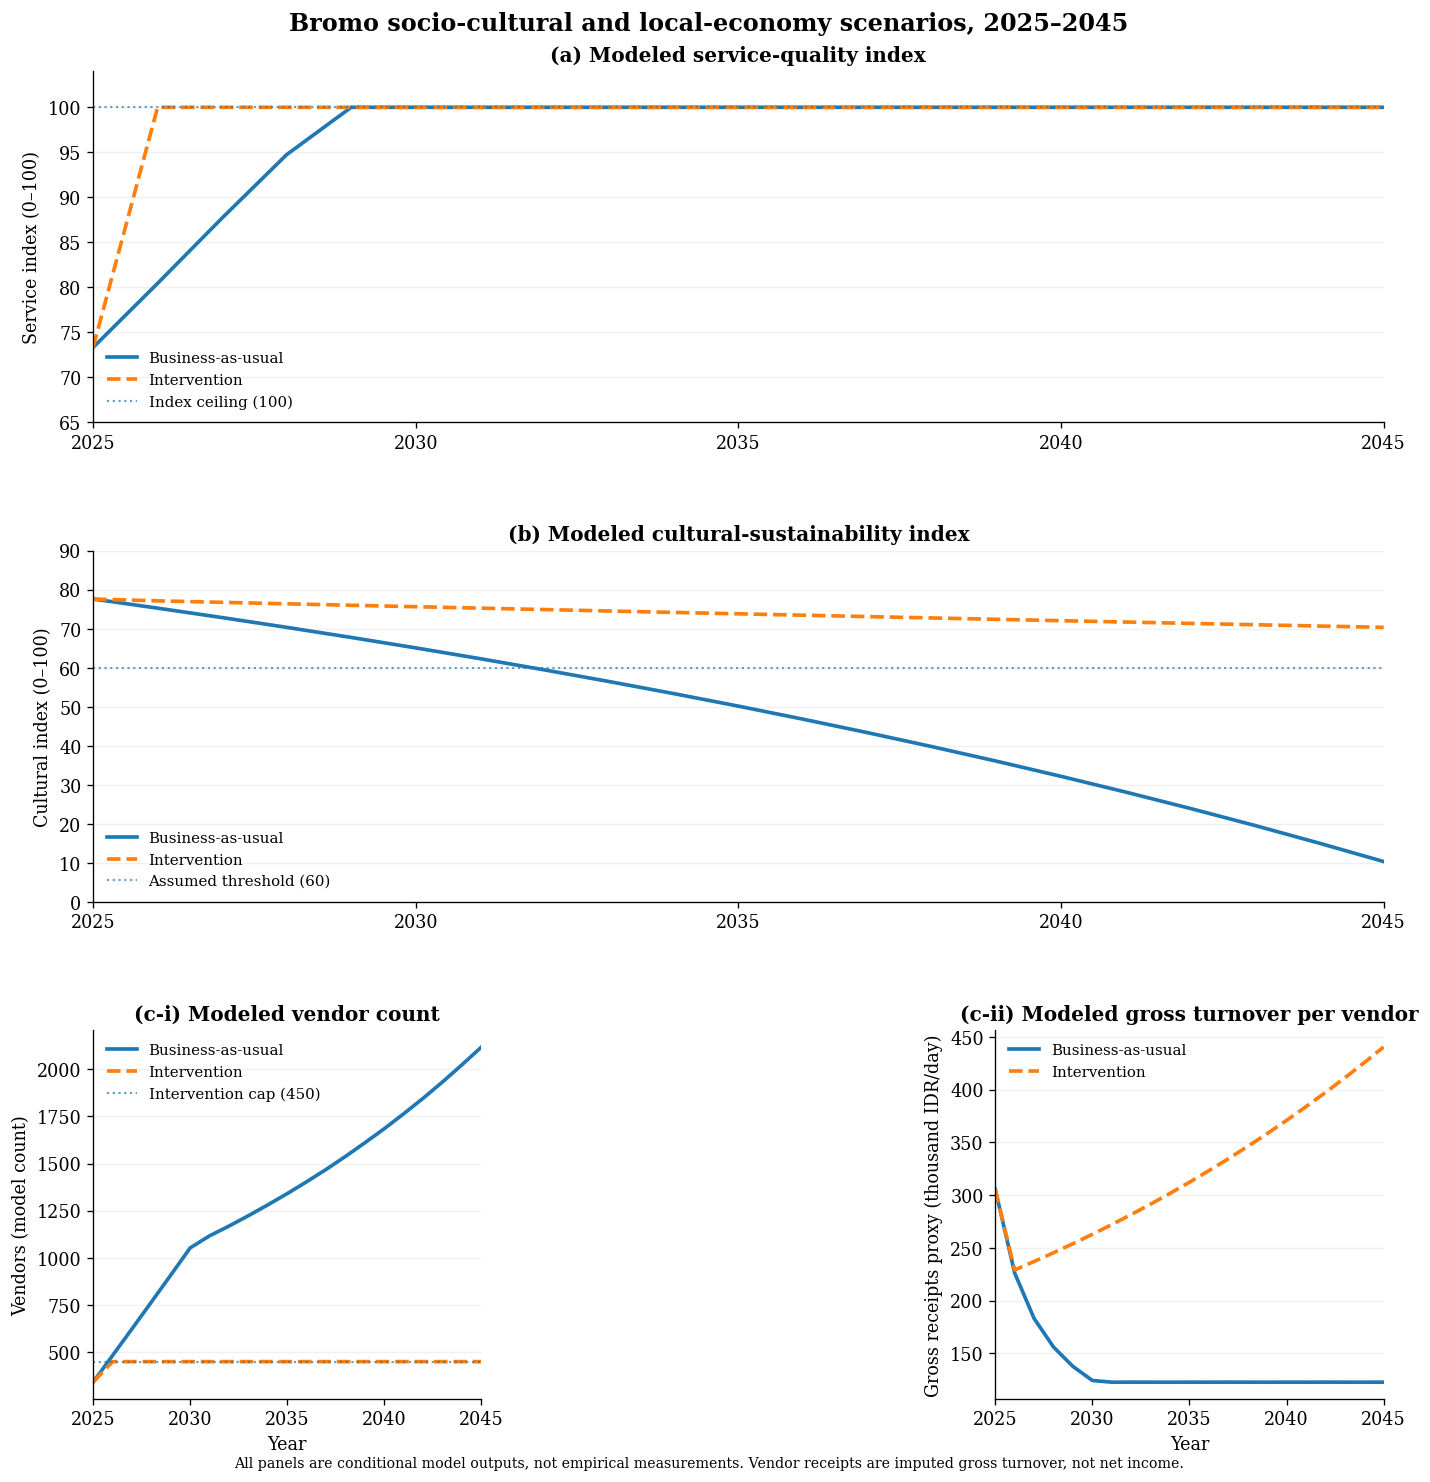

Saved image: /mnt/data/ATR_Fig8_Sociocultural_Economy_Executed_300dpi.png
Saved PDF: /mnt/data/ATR_Fig8_Sociocultural_Economy_Executed.pdf


In [5]:

plt.rcParams.update({
    'font.family':'DejaVu Serif', 'font.size':10.5,
    'axes.titlesize':12, 'axes.labelsize':10.5,
    'axes.spines.top':False,'axes.spines.right':False,
    'figure.dpi':120,'savefig.dpi':300,
})
fig=plt.figure(figsize=(11.7,12.1), layout='constrained')
layout=fig.add_gridspec(3,2,height_ratios=[1,1,1.05],wspace=0.20,hspace=0.15)
a=fig.add_subplot(layout[0,:]); b=fig.add_subplot(layout[1,:]); c=fig.add_subplot(layout[2,0]); d=fig.add_subplot(layout[2,1])
yr=wide['year']
styles={'BAU':{'ls':'-','lw':2.2},'INT':{'ls':'--','lw':2.2}}
for scenario,label in [('BAU','Business-as-usual'),('INT','Intervention')]:
    a.plot(yr,wide[f'service_quality_index_end_year_{scenario}'],
           label=label,**styles[scenario])
    b.plot(yr,wide[f'culture_index_end_year_{scenario}'],
           label=label,**styles[scenario])
    c.plot(yr,wide[f'vendor_count_end_year_{scenario}'],
           label=label,**styles[scenario])
    d.plot(yr,wide[f'gross_turnover_per_vendor_IDR_day_end_year_{scenario}']/1000,
           label=label,**styles[scenario])

a.set(title='(a) Modeled service-quality index', ylabel='Service index (0–100)',ylim=(65,104))
a.axhline(100,linestyle=':',linewidth=1.3,alpha=.7,label='Index ceiling (100)')
b.set(title='(b) Modeled cultural-sustainability index',ylabel='Cultural index (0–100)',ylim=(0,90))
b.axhline(CULTURE_REFERENCE,linestyle=':',linewidth=1.3,alpha=.7,label='Assumed threshold (60)')
c.set(title='(c-i) Modeled vendor count', ylabel='Vendors (model count)',xlabel='Year')
c.axhline(INTERVENTION_VENDOR_CAP,linestyle=':',linewidth=1.3,alpha=.7,label='Intervention cap (450)')
d.set(title='(c-ii) Modeled gross turnover per vendor',
      ylabel='Gross receipts proxy (thousand IDR/day)',xlabel='Year')
for ax in [a,b,c,d]:
    ax.set_xlim(2025,2045)
    ax.set_xticks([2025,2030,2035,2040,2045])
    ax.grid(axis='y',alpha=.18)
    ax.legend(frameon=False,fontsize=9,loc='best')
    ax.title.set_fontweight('bold')

fig.suptitle('Bromo socio-cultural and local-economy scenarios, 2025–2045',
             fontsize=14.3,fontweight='bold')
fig.text(0.5,-.006,'All panels are conditional model outputs, not empirical measurements. '
                   'Vendor receipts are imputed gross turnover, not net income.',
         ha='center',fontsize=8.5)
png=OUT/'ATR_Fig8_Sociocultural_Economy_Executed_300dpi.png'
pdf=OUT/'ATR_Fig8_Sociocultural_Economy_Executed.pdf'
fig.savefig(png,dpi=300,bbox_inches='tight')
fig.savefig(pdf,bbox_inches='tight')
plt.show()
print('Saved image:',png)
print('Saved PDF:',pdf)



## 4. Manuscript caption and interpretation

**Fig. 8.** Socio-cultural and local-economy scenario outcomes: (a) modeled service-quality index, (b) modeled cultural-sustainability index, and (c) modeled vendor numbers and gross receipts per vendor.

**Do not describe these as measured socioeconomic improvements.** The service-quality ceiling and the cultural benchmark are chosen model values. The vendor mechanism assumes a fixed per-admission expenditure allocated entirely to vendors, no independent buyer spending survey, and a hard upper bound on the number of vendors under intervention. It thus cannot establish that a vendor restriction increases actual merchant incomes or improves income distribution.

Methods and Supplementary Materials should state the **2025 reinitialization**, daily update equations, 85% hypothetical funding fraction, budget absorption, index parameterization and the fact that the three subsystem simulations share a visitor-demand driver but are **not** one independently validated integrated model.
